In [1]:
import numpy as np
import xarray as xr
from scipy.signal import savgol_filter
from scipy.interpolate import interp1d

import glob
import os
import warnings
from collections import defaultdict
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import cmocean
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D


from swot_analysis import compute_pass_spectra
from swot_analysis import load_swot_l2_expert 

In [3]:
DATA_DIR        = '/Volumes/PortableSSD/'
EXPERT_FILE     = 'SWOT_L2_LR_Expert_013_505_amazon_test.nc'
UNSMOOTHED_FILE = 'SWOT_L2_LR_Unsmoothed_013_505_amazon_test.nc'

In [5]:
ds = xr.open_dataset(DATA_DIR+EXPERT_FILE)

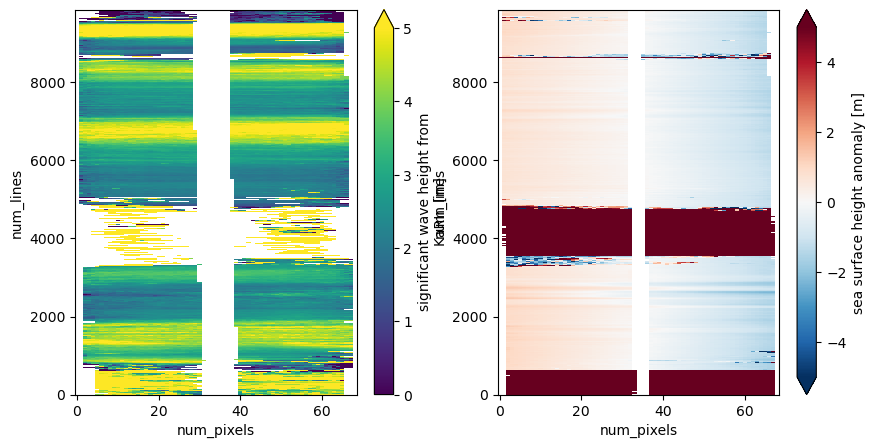

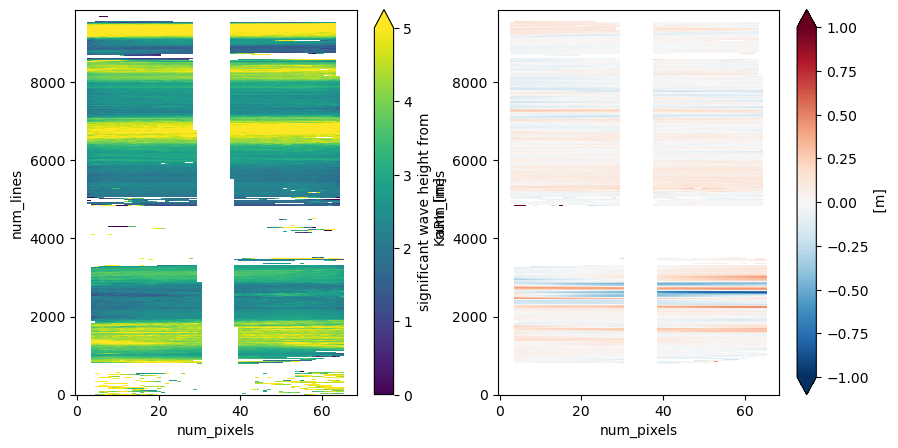

In [21]:
fig,axs = plt.subplots(1,2,figsize=(10,5))
ds.swh_karin.plot(vmax=5,ax=axs[0])
ds.ssha_karin_2.plot(vmax=5,ax=axs[1])
fig,axs = plt.subplots(1,2,figsize=(10,5))
ds.swh_karin.where((ds.swh_karin_qual==0)).plot(vmax=5,ax=axs[0])
(ds.ssha_karin_2.where((ds.ssha_karin_2_qual==0))+ds.height_cor_xover).plot(vmax=1,ax=axs[1])

In [27]:
swh = np.where((ds.swh_karin_qual==0))
ssha = np.where(swh<=5,ds.ssha_karin_2.where((ds.ssha_karin_2_qual==0)),np.nan)

TypeError: '<=' not supported between instances of 'tuple' and 'int'

In [25]:
swh

(array([   0,    0,    0, ..., 9687, 9688, 9688], shape=(354874,)),
 array([ 8,  9, 10, ...,  7,  6,  7], shape=(354874,)))

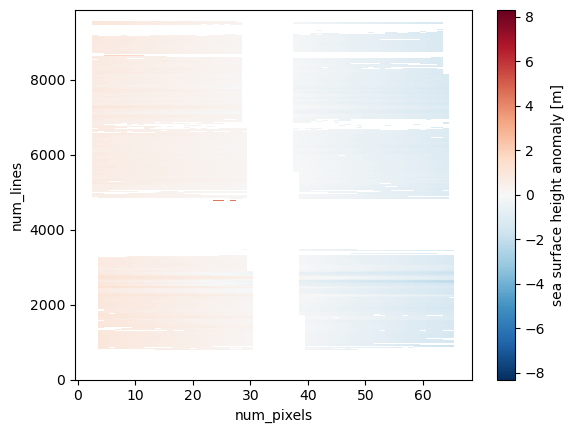

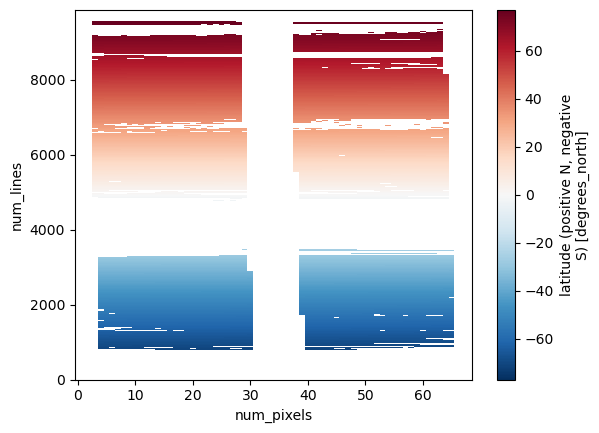

In [23]:
ds.ssha_karin_2.where((ds.swh_karin<=5) & (ds.ssha_karin_2_qual==0)).plot()
plt.figure()
ds.latitude.where((ds.swh_karin<=5) & (ds.ssha_karin_2_qual==0)).plot()